In [2]:
from transformer_lens.model_bridge import TransformerBridge

model = TransformerBridge.boot_transformers("gpt2", device="cpu")

text = "The cat sat on the mat. The cat sat on the"
logits, cache = model.run_with_cache(text)

next_token = logits[0, -1].argmax().item()

print("Prediction:", repr(model.tokenizer.decode([next_token])))
print("Attention:", cache["blocks.0.attn.hook_pattern"].shape)

/Users/yuqingpeng/Documents/fighting-rl/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1102 13:12:24.184000 3590 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|████████████████████████████████████████████████| 148/148 [00:00<00:00, 9437.73it/s]


Prediction: ' mat'
Attention: torch.Size([1, 12, 13, 13])


In [3]:
import torch

print(logits.shape)

probs = torch.softmax(logits[0, 12], dim=-1)
values, indices = probs.topk(5)

for token_id, prob in zip(indices, values):
    token = model.tokenizer.decode([token_id.item()])
    print(repr(token), round(prob.item(), 4))

torch.Size([1, 13, 50257])
' mat' 0.8315
' floor' 0.0065
' table' 0.0064
' cat' 0.0061
' bench' 0.0059


In [6]:
def children(path):
    prefix = f"{path}." if path else ""
    return sorted({
        key[len(prefix):].split(".")[0]
        for key in cache.keys()
        if key.startswith(prefix)
    })

for path in ["", "blocks", "blocks.0", "blocks.0.attn", "blocks.0.attn.q"]:
    print(path or "root", ":", children(path))

root : ['blocks', 'embed', 'hook_embed', 'hook_pos_embed', 'hook_unembed', 'ln_final', 'pos_embed', 'unembed']
blocks : ['0', '1', '10', '11', '2', '3', '4', '5', '6', '7', '8', '9']
blocks.0 : ['attn', 'hook_attn_out', 'hook_in', 'hook_mlp_out', 'hook_out', 'hook_resid_mid', 'hook_resid_post', 'hook_resid_pre', 'ln1', 'ln2', 'mlp']
blocks.0.attn : ['hook_attn_scores', 'hook_hidden_states', 'hook_in', 'hook_k', 'hook_out', 'hook_pattern', 'hook_q', 'hook_v', 'hook_z', 'k', 'o', 'q', 'v']
blocks.0.attn.q : ['hook_in', 'hook_out']


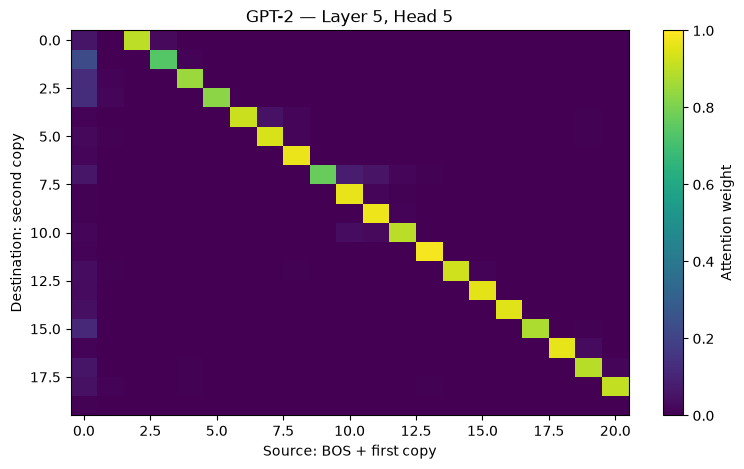

In [16]:

import torch
import matplotlib.pyplot as plt

torch.manual_seed(42)

n = 20
first = torch.randperm(20000)[:n] + 100
bos = torch.tensor([model.tokenizer.bos_token_id])

tokens = torch.cat([bos, first, first]).unsqueeze(0)
tokens = tokens.to(next(model.parameters()).device)

with torch.no_grad():
    _, cache = model.run_with_cache(
        tokens,
        names_filter="blocks.5.attn.hook_pattern",
    )

pattern = cache["blocks.5.attn.hook_pattern"][0, 5]
pattern = pattern.detach().float().cpu()

plt.figure(figsize=(9, 5))
plt.imshow(
    pattern[n + 1:, :n + 1],
    cmap="viridis",
    aspect="auto",
    vmin=0,
    vmax=1,
)
plt.xlabel("Source: BOS + first copy")
plt.ylabel("Destination: second copy")
plt.title("GPT-2 — Layer 5, Head 5")
plt.colorbar(label="Attention weight")
plt.show()


In [17]:
view = pattern[n + 1:, :n + 1]

print(view[:5].argmax(dim=1).tolist())

[2, 3, 4, 5, 6]
